In [16]:
# ==============================================================================
#                     1. HERRAMIENTAS Y LIBRERÍAS 
# ==============================================================================

# Cargamos herramientas básicas del sistema para manejar carpetas, saber si usas Mac o Windows,
# lanzar dados para eventos aleatorios y hacer pausas de tiempo en el juego.
import os
import platform
import random
import subprocess
import time

#import os >>> ofrece acceso a herramientas del sistema operativo. Permite gestionar rutas de archivos (como os.path.join), comprobar si un archivo existe en el disco (os.path.exists) y obtener carpetas de usuario (os.path.expanduser).
#import platform >>> detecta qué sistema operativo ejecuta el código (Windows, macOS o Linux). Es clave para saber qué comando externo invocar si falla Jupyter.
#import subprocess >>> permite lanzar comandos del sistema operativo desde Python. Se utiliza como plan de emergencia en macOS o Linux para abrir un visor de archivos por defecto.
#import random >>> enera números aleatorios. Se usa en la simulación para los eventos inesperados (mutaciones, fatiga inmunológica, etc.).
#import time >>> genera pausas temporales >> el método time.sleep(1) detiene la ejecución 1 segundo para dar dinamismo entre imagen y texto.

# Intentamos cargar la herramienta de Jupyter (IPython) que permite pegar fotos dentro de la pantalla del juego.
try:
    from IPython.display import Image as DisplayImage, display

    HAS_IPYTHON = True  # Estamos en Jupyter y podemos mostrar fotos directamente en la pantalla de juego.
except ImportError:
    HAS_IPYTHON = (
        False  # Si no estamos en Jupyter, marcamos que no está disponible.
    )

# Intentamos cargar Pillow (PIL), que es una librería alternativa para manejar imágenes si la primera falla.
try:
    from PIL import Image as PILImage

    HAS_PIL = True  # Pillow está instalado.
except ImportError:
    HAS_PIL = False  # Pillow no está instalado.


# ------------------------------------------------------------------------------
#                         DICCIONARIO DE IMAGENES
# ------------------------------------------------------------------------------

# Este es el álbum del juego. A la izquierda ponemos un "nombre clave" para el juego,
# y a la derecha el nombre real de la foto que tenemos guardada en la carpeta.
# Si el día de mañana cambiamos la foto de una pista, solo editamos este nombre aquí 
# esto facilita cambios en el juego sin tocar nada mas del codigo.

IMAGENES = {
    "instrucciones": "instrucciones.jpeg",
    "historia_intro": "historia_cap1.jpg",
    "pista_hora_1": "pista1.jpeg",
    "pista_hora_2": "pista2.jpeg",
    "pista_hora_3": "pista3.jpeg",
    "pista_hora_4": "pista4.jpg",
    "final_summary": "partida_final.jpeg",
}


# ------------------------------------------------------------------------------
#                         BUSCADOR DE ARCHIVOS
# ------------------------------------------------------------------------------


def encontrar_ruta_imagen(nombre_archivo):
    """Esta función rastrea tu ordenador para encontrar la foto, sin importar

    dónde tengas la carpeta del proyecto.
    """
    # 1. ¿Está la foto justo en la misma carpeta donde estás ejecutando este programa?
    if os.path.exists(nombre_archivo):
        return os.path.abspath(nombre_archivo)  # ¡Sí! Devuelve la ruta exacta.

    # 2. Si no la encuentra ahí, busca dentro de la carpeta especial llamada "PYTHON"
    # que suele estar en tu usuario (Descargas, Documentos, Escritorio...).
    user_home = os.path.expanduser("~")  # Averigua cómo se llama tu usuario en el ordenador
    rutas_python = [
        os.path.join(user_home, "PYTHON"), 
        os.path.join(user_home, "Documents", "PYTHON"),
        os.path.join(user_home, "Documentos", "PYTHON"),
        os.path.join(user_home, "Desktop", "PYTHON"),
        os.path.join(user_home, "Escritorio", "PYTHON"),
        os.path.join(user_home, "Downloads", "PYTHON"),
        os.path.join(user_home, "Descargas", "PYTHON")
    ]

    # Revisa una por una las carpetas de la lista
    for ruta_dir in rutas_python:
        ruta_posible = os.path.join(ruta_dir, nombre_archivo) #rutas de archivos (como os.path.join)
        if os.path.exists(
            ruta_posible ):  # Si encuentra la foto en esa carpeta...
            return ruta_posible  # Nos da la dirección exacta de la imagen.

    # Si busca por todos lados y no la encuentra, devuelve "Nada" (None)
    return None


# ------------------------------------------------------------------------------
#                         MOSTRAR IMAGEN EN PANTALLA
# ------------------------------------------------------------------------------
 

def mostrar_imagen(clave_imagen):
    """Recibe la clave de la foto (ej: 'pista_hora_1') y se encarga de proyectarla

    en la pantalla según el tipo de ordenador o programa que uses.
    """
    # Buscamos en nuestro "Catálogo" (IMAGENES) qué archivo corresponde a esa clave
    nombre_archivo = IMAGENES.get(clave_imagen)

    # Si no hay ninguna foto asignada a ese nombre en el catálogo, avisa y se sale.
    if not nombre_archivo:
        print(f" [Aviso]: No hay imagen asignada a '{clave_imagen}'.")
        return

    # Mandamos al "Detective" (encontrar_ruta_imagen) a buscar el archivo físico en el disco
    ruta_completa = encontrar_ruta_imagen(nombre_archivo)

    # Si el detective no encontró la foto por ningún lado, saca un aviso en pantalla y no rompe el juego.
    if not ruta_completa:
        print(f" [Aviso]: No se encontró la imagen '{nombre_archivo}'.")
        return

    # Si todo está correcto, intentamos mostrarla según el programa que estés usando:
    try:
        if HAS_IPYTHON:
            # OPCIÓN A: Si usas Jupyter, pega la imagen directamente debajo del texto con un ancho de 500px.
            display(DisplayImage(filename=ruta_completa, width=500))

        elif HAS_PIL:
            # OPCIÓN B: Si no hay Jupyter pero está la librería Pillow, la abre en una ventana independiente.
            img = PILImage.open(ruta_completa)
            img.show()

        else:
            # OPCIÓN C (si no funciona ninguna de las anteriores): Le pide directamente al sistema operativo (Mac/Windows) que la abra.
            sistema = platform.system()
            if sistema == "Windows":
                os.startfile(ruta_completa)  # Comando para Windows
            elif sistema == "Darwin":
                subprocess.run(
                    ["open", ruta_completa], check=False
                )  # Comando para Mac
            else:
                subprocess.run(
                    ["xdg-open", ruta_completa], check=False
                )  # Comando para Linux

    except Exception as e:
        # Si ocurre un problema raro al abrir la foto, imprime el error y permite seguir jugando.
        print(f"No se pudo mostrar la imagen: {e}")


# ==============================================================================
#                     2. CLASES PRINCIPALES 
# ==============================================================================
# ------------------------------------------------------------------------------
#                 PLANTILLA DEL ENEMIGO (El Virus)
# ------------------------------------------------------------------------------
class Virus:
    """Esta clase es el molde para fabricar al virus enemigo."""

    def __init__(self, load, replication_rate, name="Virus Estándar"):
        # load: La carga viral o cantidad de virus presentes en el cuerpo
        self.load = load

        # replication_rate: El multiplicador de velocidad a la que crece
        self.replication_rate = replication_rate

        # name: El nombre identificativo del virus
        self.name = name

    def replicate(self):
        """Hace que el virus se multiplique multiplicando su carga actual por su tasa de réplica."""
        self.load *= self.replication_rate

# ------------------------------------------------------------------------------
#           PLANTILLA DE NUESTRA DEFENSA (El Sistema Inmunitario)
# ------------------------------------------------------------------------------
class ImmuneSystem:
    """Esta clase es el molde que gestiona todas nuestras tropas y la salud del cuerpo."""

    def __init__(
        self, t_cells, nk_cells, macrophages, cytokines, tissue_damage=0
    ):
        self.t_cells = t_cells  # Cantidad de Linfocitos T (fuerza adaptativa)
        self.nk_cells = nk_cells  # Cantidad de Células NK (patrullas rápidas)
        self.macrophages = macrophages  # Cantidad de Macrófagos (limpiadores)
        self.cytokines = (
            cytokines  # Nivel de inflamación o alarma celular (citoquinas)
        )
        self.tissue_damage = (
            tissue_damage  # Daño acumulado en los tejidos del cuerpo (0 a 100)
        )

    def innate_response(self, virus):
        """Ataque automático de la primera línea de defensa (Células NK y Macrófagos)."""
        # Cada célula NK reduce un 0.04 de virus
        nk_effect = self.nk_cells * 0.04

        # Cada macrófago reduce un 0.03 de virus
        macro_effect = self.macrophages * 0.03

        total_reduction = nk_effect + macro_effect

        # Restamos el ataque a la carga del virus (usamos max(0, ...) para no tener virus negativos)
        virus.load = max(0, virus.load - total_reduction)

        # Al luchar, la inmunidad innata genera algo de inflamación/citoquinas (+0.02 por tropa)
        self.cytokines += (self.nk_cells + self.macrophages) * 0.02

    def adaptive_response(self, virus):
        """Ataque de precisión pesada de los Linfocitos T."""
        # Cada Linfocito T causa un daño masivo de 0.08 al virus
        t_effect = self.t_cells * 0.08
        virus.load = max(0, virus.load - t_effect)

        # Genera algo de inflamación adicional por el combate (+0.02 por Linfocito T)
        self.cytokines += self.t_cells * 0.02

    def apply_inflammation_effects(self):
        """Calcula si la inflamación acumulada (citoquinas) le hace daño colateral al cuerpo."""
        if self.cytokines > 80:
            self.tissue_damage += (
                12  # Inflamación crítica: +12 de daño al cuerpo
            )
        elif self.cytokines > 50:
            self.tissue_damage += (
                6  # Inflamación alta: +6 de daño al cuerpo
            )
        elif self.cytokines > 30:
            self.tissue_damage += (
                3  # Inflamación moderada: +3 de daño al cuerpo
            )

    
# ==============================================================================
#                            3. INTERFAZ Y ACCIONES 
# ==============================================================================

# ------------------------------------------------------------------------------
# DIBUJANTE DE BARRAS DE VIDA/CARGA: Dibuja las barras tipo [#####-----]
# ------------------------------------------------------------------------------
def ascii_bar(value, max_value=200, length=40):
    """Toma un valor (como la carga viral o el daño al cuerpo) y lo convierte en

    una barrita visual hecha de almohadillas `#` y guiones `-`.
    """
    # 1. Calculamos la proporción (porcentaje): dividimos lo que tenemos entre el máximo posible.
    # Usamos min(..., 1) para que si el valor supera el máximo, la barra no se salga de la pantalla (se quede al 100%).
    proportion = min(value / max_value, 1)

    # 2. Convertimos ese porcentaje en la cantidad de almohadillas `#` que hay que rellenar.
    # Por ejemplo, si la barra mide 40 de largo y estamos al 50%, rellenará 20 almohadillas.
    filled = int(proportion * length)

    # 3. Monta la barra completa: junta los corchetes `[`, las almohadillas llenas `#`,
    # los guiones restantes `-` y cierra el corchete `]`.
    return "[" + "#" * filled + "-" * (length - filled) + "]" 
    
    #para mostrar las # se usa el filled en logica directa >>> para rellenar con - se utiliza el filled en logica indirecta.


# ------------------------------------------------------------------------------
# PANTALLA DE ESTADO: Muestra el estado del jugador del momento de la batalla
# ------------------------------------------------------------------------------
def show_status(virus, immune, hour):
    """Imprime en la pantalla del jugador un informe detallado con el número de

    hora actual, la salud del cuerpo, el nivel del virus y los recursos
    defensivos.
    """
    # Imprime el encabezado con la hora actual de la simulación
    print(f"\n=== Hora {hour} ===")

    # Nos dice qué tipo de virus estamos combatiendo
    print(f"Virus: {virus.name}")

    # Muestra la carga viral con decimales (.1f) y le pega al lado la barrita visual (ascii_bar en realidad esta diseñada para )
    print(f"Carga viral: {virus.load:.1f} {ascii_bar(virus.load)}")

    # Muestra los niveles actuales de nuestras tropas defensivas y citoquinas
    print(f"Linfocitos T: {immune.t_cells:.1f}")
    print(f"Células NK: {immune.nk_cells:.1f}")
    print(f"Macrófagos: {immune.macrophages:.1f}")
    print(f"Citoquinas: {immune.cytokines:.1f}")

    # Muestra cuánto daño tiene el cuerpo humano (con su barrita visual propia hasta un máximo de 100)
    print(
        f"Daño tisular: {immune.tissue_damage:.1f}"
        f" {ascii_bar(immune.tissue_damage, max_value=100)}"
    )


# ------------------------------------------------------------------------------
# MENÚ DE OPCIONES: Le pregunta al jugador qué quiere hacer
# ------------------------------------------------------------------------------
def ask_player_action():
    """Muestra el panel de órdenes estratégicas en pantalla y espera a que el

    jugador escriba un número del 1 al 4.
    """
    print("\nAcciones disponibles:")
    print("1) Activar linfocitos T (Ataque masivo especializado)")
    print("2) Potenciar células NK (Patrullas citotóxicas)")
    print("3) Activar macrófagos (Fagocitosis y alarma)")
    print("4) Aumentar interferones (Freno de replicación)")

    # Pide la entrada por teclado y devuelve lo que haya escrito el usuario (ejemplo: "4")
    return input("Elige una acción (1-4): ")


# ------------------------------------------------------------------------------
# EJECUTOR DE ÓRDENES: Aplica los efectos de la elección del jugador
# ------------------------------------------------------------------------------
def apply_action(choice, virus, immune):
    """Lee el número elegido por el jugador (choice) y modifica las estadísticas

    del sistema inmune o del virus según la opción elegida.
    """
    # OPCIÓN 1: Refuerza los Linfocitos T (potencia bruta adaptativa)
    if choice == "1":
        immune.t_cells += 8  # Sumamos 8 tropas de Linfocitos T
        immune.cytokines += 3  # Genera 3 de inflamación/citoquinas
        print("Activas linfocitos T.")

    # OPCIÓN 2: Refuerza las Células NK (patrullas de ataque rápido)
    elif choice == "2":
        immune.nk_cells += 5  # Sumamos 5 células NK
        immune.cytokines += 2  # Genera 2 de inflamación
        print("Potencias células NK.")

    # OPCIÓN 3: Refuerza los Macrófagos (aspiradoras de la inmunidad innata)
    elif choice == "3":
        immune.macrophages += 5  # Sumamos 5 macrófagos
        immune.cytokines += 2  # Genera 2 de inflamación
        print("Activas macrófagos.")

    # OPCIÓN 4: Frena la velocidad de multiplicación del virus
    elif choice == "4":
        # Multiplica la tasa de réplica por 0.75 (reduce la velocidad a un 75%, frenándolo un 25%)
        virus.replication_rate *= 0.75
        immune.cytokines += 4  # Genera 4 de inflamación (los interferones dan mucha alarma)
        print("Aumentas interferones.")

    # SI ESCRIBE CUALQUIER OTRA COSA (o se equivoca de tecla)
    else:
        print("Acción no válida. Se pierde el turno.")


# ------------------------------------------------------------------------------
# Simula imprevistos biológicos aleatorios
# ------------------------------------------------------------------------------
def random_events(virus, immune):
    """En cada turno tira unos 'dados invisibles' (random.random) para ver si

    ocurre algún contratiempo o evento sorpresa.
    """
    # 1. EVENTO MUTACIÓN: Hay un 10% de probabilidad (0.1) de que el virus sea más agresivo
    if random.random() < 0.1:
        virus.replication_rate *= 1.1  # El virus acelera su réplica un 10%
        print("EVENTO: El virus ha mutado.")

    # 2. EVENTO FATIGA: Hay un 8% de probabilidad (0.08) de perder Linfocitos T por cansancio celular
    if random.random() < 0.08:
        # Restamos 3 Linfocitos T, pero usamos max(0, ...) para asegurarnos de no tener tropas negativas
        immune.t_cells = max(0, immune.t_cells - 3)
        print("EVENTO: Fatiga inmunológica.")

    # 3. EVENTO TORMENTA DE CITOQUINAS: Si hay más de 90 de citoquinas (mucha inflamación),
    # hay un 30% de probabilidad (0.3) de que el propio cuerpo se auto-dañe fuertemente
    if immune.cytokines > 90 and random.random() < 0.3:
        immune.tissue_damage += 15  # Suma 15 puntos directos de daño al cuerpo
        print("EVENTO: Tormenta de citoquinas.")


# ------------------------------------------------------------------------------
#                         FIN DEL JUEGO
# ------------------------------------------------------------------------------
def game_over(virus, immune, hour):
    """Evalúa al final del turno si se ha cumplido alguna condición extrema de

    victoria o derrota.
    """
    # CONDICIÓN DE VICTORIA RÁPIDA: Si el virus casi ha desaparecido (menos de 2 de carga)
    if virus.load <= 2:
        return "controlada"  # Victoria

    # CONDICIÓN DE DERROTA: Si el cuerpo recibe un daño fatal (100 de daño o más)
    if immune.tissue_damage >= 100:
        return "fallo_organico"  # Derrota

    # CONDICIÓN DE TIEMPO LÍMITE: Si la partida supera las 72 horas sin resolverse
    if hour >= 72:
        return "cronica"  # Infección crónica

    # SI NINGUNA SE CUMPLE: Devuelve "Nada" (None) y el juego continúa normalmente al siguiente turno
    return None


# ==============================================================================
#                        4. PISTAS DINÁMICAS Y SCORE 
# ==============================================================================

# ------------------------------------------------------------------------------
#                        EVALUA LA ESTRATEGIA DEL JUGADOR
# ------------------------------------------------------------------------------
def check_step_feedback(current_hour, choice):
    """Esta función comprueba qué hora es (current_hour) y qué botón pulsó el jugador (choice).

    Muestra la foto correspondiente, espera 1 segundo y le dice si acertó o se
    equivocó.
    """

    # 1. Creamos la(ideal_sequence) en formato de diccionario >>> con cada hora
    # Para cada hora (1, 2, 3, 4) guardamos una "tupla" (un paquete cerrado con 4 cosas):
    #  - La opción correcta ("4", "3", "2", "1")
    #  - El mensaje de felicitación si acierta
    #  - La pista para la siguiente hora
    #  - La clave de la imagen que hay que proyectar
    
    ideal_sequence = {
        1: ("4", "¡Excelente decisión! Aumentar los interferones frena la replicación viral y frena la invasión.", 
               " Pista para la Hora 2: Con el virus frenado, necesitamos enviar a la primera línea de patrullaje a devorar al enemigo y dar la alarma.",
               "pista_hora_1"),
        2: ("3", "¡Perfecto! Los macrófagos están limpiando la zona y liberando citoquinas de alerta.", 
               " Pista para la Hora 3: Es hora de activar las patrullas citotóxicas para buscar y destruir células infectadas.",
               "pista_hora_2"),
        3: ("2", "¡Gran maniobra! Las células NK destruyen los focos de infección antes de que se extiendan.", 
               " Pista para la Hora 4: Para rematar la infección, despliega la respuesta adaptativa especializada.",
               "pista_hora_3"),
        4: ("1", "¡Estrategia impecable! Los linfocitos T terminan con la amenaza de forma masiva y específica.", 
               " ¡Has completado la secuencia táctica perfecta!",
               "pista_hora_4")
    }
    # Comprobamos si la hora actual está dentro de nuestras 4 horas planificadas (1, 2, 3 o 4)
    if current_hour in ideal_sequence:

        # "Desempaquetamos" las 4 variables de la chuleta para la hora actual:
        # target_choice = número correcto | success_msg = texto acierto | next_hint = pista | clave_img = id foto
        target_choice, success_msg, next_hint, clave_img = ideal_sequence[
            current_hour
        ]

        # PASO A: Proyectamos primero la imagen en la pantalla
        mostrar_imagen(clave_img)

        # PASO B: Hacemos una pausa dramática de 1 segundo para que la imagen se vea antes del texto
        time.sleep(1)

        # PASO C: Evaluamos si la elección del jugador coincide exactamente con la opción correcta
        if choice == target_choice:
            # ¡Si acertó! Imprimimos en verde/positivo la felicitación y la pista
            print(f"\n {success_msg}")
            print(f"{next_hint}\n")
        else:
            # Si no coincide = se equivoco >>> explicamos por qué su acción no fue la mejor en esta hora
            print("\n DECISIÓN SUBÓPTIMA:")
            if current_hour == 1:
                print( "   'Atacar directamente sin frenar primero la replicación"
                       " hace que el virus crezca demasiado rápido.'")
            elif current_hour == 2:
                print( "   'Falta coordinación innata; deberías haber llamado a"
                       " los macrófagos para dar la alarma.'")
            elif current_hour == 3:
                print( "   'Antes del ataque masivo adaptativo, necesitabas a las"
                       " patrullas citotóxicas NK para contener los focos.'")
            elif current_hour == 4:
                print( "   'Para la ofensiva final especializada necesitabas"
                       " activar los linfocitos T.'")

            print("   (La puntuación de tu secuencia se verá reducida)\n")


# ------------------------------------------------------------------------------
#                         PUNTUACIÓN FINAL
# ------------------------------------------------------------------------------
def calculate_score(player_sequence, hour, result):
    """Revisa la lista de elecciones que hizo el jugador durante la partida y
       compara su orden contra la secuencia perfecta (4 -> 3 -> 2 -> 1). """

    # 1. SI PERDIÓ LA PARTIDA (el virus no se controló o el cuerpo murió)
    if result != "controlada":
        # Le resta 2 puntos por cada hora transcurrida.
        # Usamos max(0, ...) para asegurarnos de que la nota nunca baje de 0 (no da notas negativas).
        return max(0, 100 - (hour * 2))

    # 2. SI GANÓ, ANALIZAMOS SU TÁCTICA:
    ideal_sequence = ["4", "3", "2", "1"]  # La combinación ganadora

    # Extraemos solo las primeras 4 elecciones que hizo el jugador (ignora si jugó horas de más)
    first_four = player_sequence[:4]

    # SI HIZO LA COMBINACIÓN PERFECTA (4, 3, 2, 1) en orden exacto:
    if first_four == ideal_sequence:
        return 100  # Matrícula de honor / Puntuación máxima

    # SI NO FUE PERFECTA, CONTAMOS ACIERTOS:
    # `zip` junta las respuestas del jugador con las correctas posición a posición.
    # `sum(...)` cuenta cuántos números coincidieron en el orden adecuado (ejemplo: acertó 2 de 4).
    matches = sum(1 for p, i in zip(first_four, ideal_sequence) if p == i)

    # Si tardó más de 4 horas en controlar la infección, aplicamos un castigo por tiempo (5 ptos por hora extra)
    time_penalty = max(0, (hour - 4) * 5)

    # Calculamos la nota base: 20 puntos por cada acierto + 10 de base - la penalización de tiempo
    score = (matches * 20) + 10 - time_penalty

    # Ajustamos el resultado final para que no sea excesivo:
    # `min(95, score)` asegura que si no fue perfecta nunca llegue a 100 (máximo 95).
    # `max(10, score)` asegura que si ganó la partida, al menos tenga un 10 por haber controlado la infeccion.
    return max(10, min(95, score))



# ==============================================================================
#                    5. INSTRUCCIONES Y MODO HISTORIA
# ==============================================================================

# ------------------------------------------------------------------------------
#               PANTALLA 1: INSTRUCCIONES y Reglas Básicas
# ------------------------------------------------------------------------------
def show_instructions():
    """Esta función es el 'Tutorial Inicial'.

    Muestra una foto con las reglas del juego y dibuja un cuadro de texto con el
    mensaje del Maestro que nos explica qué tenemos que hacer antes de jugar.
    """
    # 1. Proyecta la imagen asignada a las instrucciones (instrucciones.jpeg)
    mostrar_imagen("instrucciones")

    # 2. Imprime en pantalla las líneas decorativas y el texto formateado como un cuadro de diálogo
    print("\n=================================================================================")
    print("                      === TRANSMISIÓN DESDE EL NÚCLEO ===                        ")
    print("=================================================================================")
    print("┌──────────────────────────────────────────────────────────────────────────────┐")
    print("│ MAESTRO: \"¡Bienvenidos a bordo de la nave de mando!                          │")
    print("│                                                                              │")
    print("│ Como comandante del sistema inmunitario, tu misión es coordinar la defensa   │")
    print("│ del organismo hora a hora contra la amenaza invasora.                        │")
    print("│                                                                              │")
    print("│ Reglas de la misión:                                                         │")
    print("│ - Dispones de 4 decisiones estratégicas en tu panel de control.              │")
    print("│ - Cada hora evaluarás el estado del cuerpo y ejecutarás una orden táctica.   │")
    print("│ - Debes controlar la carga viral evitando que el daño tisular sea fatal.     │")
    print("│ - Te daré indicaciones y consejos según cómo evolucione la batalla.\"         │")
    print("└──────────────────────────────────────────────────────────────────────────────┘\n")
    input("Pulsa ENTER para continuar al Informe de Misión...\n")

    # 3. Pone el juego en "Pausa": input() hace que el programa no avance a la siguiente pantalla
    # hasta que el jugador presione la tecla ENTER en su teclado.
    input("Pulsa ENTER para continuar al Informe de Misión...\n")


# ------------------------------------------------------------------------------
#           PANTALLA 2: Introducción al Modo Historia (Capítulo 1)
# ------------------------------------------------------------------------------
def story_mode_intro():
    """Esta función ambienta el inicio de la batalla.

    Presenta el problema (la llegada del virus) y le da al jugador su primera
    pista estratégica clave.
    """
    # 1. Proyecta la imagen de la intro (historia_cap1.jpg)
    mostrar_imagen("historia_intro")

    # 2. Muestra la narrativa contextualizando la gravedad de la infección
    print("\n=================================================================================")
    print("                       === CAPÍTULO 1: LA INVASIÓN ===                           ")
    print("=================================================================================")
    print("┌──────────────────────────────────────────────────────────────────────────────┐")
    print("│ MAESTRO: \"¡Alarma roja en el sector respiratorio!                            │")
    print("│                                                                              │")
    print("│ Un patógeno agresivo ha logrado atravesar las barreras primarias y se está   │")
    print("│ multiplicando a una velocidad alarmante por todo el torrente sanguíneo.      │")
    print("│                                                                              │")
    print("│  CONSEJO DEL MAESTRO (Hora 1):                                               │")
    print("│ 'El virus se multiplica a gran velocidad. Antes de enviar nuestras tropas a  │")
    print("│ ciegas, debemos frenar drásticamente su ritmo de replicación.'\"              │")
    print("└──────────────────────────────────────────────────────────────────────────────┘\n")
    input("Pulsa ENTER para iniciar los sistemas y comenzar la simulación...\n")

    # 3. Otra pausa interactiva. El jugador se toma su tiempo para leer el consejo y pulsa ENTER cuando esté listo.
    input("Pulsa ENTER para iniciar los sistemas y comenzar la simulación...\n")


# ------------------------------------------------------------------------------
#         PANTALLA 3: Informe Final de Partida (Game Over / Resumen)
# ------------------------------------------------------------------------------
def final_summary(result, virus, immune, hour, score):
    """Esta función se ejecuta al terminar las 4 horas del juego (o si se acaba

    antes).

    Recibe los datos finales (resultado, estado del virus y defensas, horas y la
    nota) y dibuja el reporte final de rendimiento.
    """
    print("\n==============================")
    print("      RESUMEN DE LA PARTIDA")
    print("==============================")

    # 1. EVALUACIÓN DEL VEDICTO: Revisa qué texto le pasó la función game_over()
    if result == "controlada":
        print(" La infección ha sido controlada con éxito.")  # Mensaje de victoria
    elif result == "fallo_organico":
        print(
            " El daño tisular alcanzó niveles incompatibles con la vida."
        )  # Mensaje de derrota
    elif result == "cronica":
        print(
            " La infección se volvió crónica tras 72 horas."
        )  # Mensaje de tiempo agotado

    # 2. Proyecta la imagen decorativa del final (partida_final.webp)
    mostrar_imagen("final_summary")

    # 3. IMPRESIÓN DE DATOS ESTADÍSTICOS:
    # Usamos f-strings f"{variable:.1f}" para volcar los valores exactos con 1 solo decimal
    print("\n--- Estado final ---")
    print(f"Horas transcurridas: {hour}")
    print(f"Carga viral final: {virus.load:.1f}")
    print(f"Linfocitos T: {immune.t_cells:.1f}")
    print(f"Células NK: {immune.nk_cells:.1f}")
    print(f"Macrófagos: {immune.macrophages:.1f}")
    print(f"Citoquinas: {immune.cytokines:.1f}")
    print(f"Daño tisular: {immune.tissue_damage:.1f}")

    # 4. MUESTRA LA NOTA OBTENIDA (SCORE):
    print("\n==============================")
    print(f" PUNTUACIÓN DE ESTRATEGIA: {score}/100")

    # Si la nota es exactamente 100, añade una mención honorífica especial
    if score == 100:
        print(
            " ¡ESTRATEGIA INMUNOLÓGICA PERFECTA! Parece que no eres tan inútil como pensaba =)"
        )
    print("==============================\n")



# ==============================================================================
#                            6. PROGRAMA PRINCIPAL 
# ==============================================================================

# ------------------------------------------------------------------------------
#                                MENÚ PRINCIPAL
# ------------------------------------------------------------------------------
def main_menu():
    """Dibuja el menú inicial de bienvenida en la consola y se queda esperando

    a que el usuario presione 1 para jugar o 2 para salir.
    """
    print("\n==============================")
    print(" SIMULADOR DE RESPUESTA INMUNE ")
    print("==============================")
    print("1) Iniciar historia")
    print("2) Salir")

    # Muestra el texto de pregunta, espera a que el usuario escriba y devuelve el resultado (ejemplo: "1")
    return input("Selecciona una opción (1-2): ")


# ------------------------------------------------------------------------------
#                          BUCLE PRINCIPAL DEL JUEGO
# ------------------------------------------------------------------------------
def main():
    """Esta es la función principal.

    Se encarga de arrancar el menú, crear al virus y al cuerpo humano,
    controlar las 4 horas de la batalla y calcular el resultado final.
    """

    # Bucle infinito del menú: Mantiene el juego abierto hasta que el jugador decida pulsar "2" (Salir).
    while True:

        # Lanzamos el menú y guardamos en 'choice' la opción elegida por el jugador
        choice = main_menu()

        # ----------------------------------------------------------------------
        # OPCIÓN 1: El jugador quiere empezar a jugar
        # ----------------------------------------------------------------------
        if choice == "1":

            # PASO 1: Mostramos las pantallas narrativas antes de empezar
            show_instructions()  # Muestra el tutorial y las reglas del juego
            story_mode_intro()  # Muestra la intro de la historia del Capítulo 1

            # PASO 2: Nace la partida (Creación de los "Personajes" u Objetos)
            # Creamos al enemigo: Un virus con carga inicial de 120 y que se multiplica a velocidad 1.25
            virus = Virus(
                load=120, replication_rate=1.25, name="Virus Estándar"
            )

            # Creamos nuestras defensas: 10 Linfocitos T, 8 Células NK, 8 Macrófagos, 10 Citoquinas y 0 Daño
            immune = ImmuneSystem(
                t_cells=10,
                nk_cells=8,
                macrophages=8,
                cytokines=10,
                tissue_damage=0,
            )

            # Preparamos una libreta vacía ([]) para ir guardando la lista de botones que presione el jugador
            action_history = []

            # Dejamos la variable del resultado vacía (None) porque la partida acaba de empezar
            result = None

            print("\nIniciando simulación...\n")

            # ------------------------------------------------------------------
            # BUCLE DE LA BATALLA: Se repite exactamente 4 veces (Hora 1 a Hora 4)
            # ------------------------------------------------------------------
            for hour in range(1, 5):

                # 1. Enseña el marcador actualizado (Carga viral, defensas y daño)
                show_status(virus, immune, hour)

                # 2. Le pregunta al jugador qué orden quiere dar (1, 2, 3 o 4)
                action = ask_player_action()

                # Guardamos esa orden en la libreta de historial para luego calcular la nota final
                action_history.append(action)

                # 3. Muestra la imagen táctica de la hora, espera 1 segundo y da el mensaje de feedback
                check_step_feedback(hour, action)

                # 4. Aplica el efecto del botón que apretó el jugador (ej: refuerza defensas o frena al virus)
                apply_action(action, virus, immune)

                # 5. TURNO DE LA BIOLOGÍA (Simulación automática del cuerpo y del virus):
                immune.innate_response(
                    virus
                )  # Los macrófagos y las células NK atacan al virus
                virus.replicate()  # El virus intenta multiplicarse en el cuerpo
                immune.adaptive_response(
                    virus
                )  # Los linfocitos T hacen su ataque especializado
                immune.apply_inflammation_effects()  # Si hay muchas citoquinas, el cuerpo sufre daño
                random_events(
                    virus, immune
                )  # Lanza los dados para ver si hay mutación o fatiga

                # 6. Comprobamos si el juego debe terminar de golpe (ej: si el cuerpo destruyó al virus o si murió)
                result = game_over(virus, immune, hour)

                # Si 'game_over' devuelve una causa de finalización ("controlada" o "fallo_organico"),
                # la orden 'break' rompe inmediatamente el bucle de las 4 horas sin esperar a la siguiente.
                if result:
                    break

                # Pausa cinemática de 1 segundo antes de pintar en pantalla los datos de la siguiente hora
                time.sleep(1)

            # ------------------------------------------------------------------
            # EVALUACIÓN FINAL: Se ejecuta al terminar las 4 horas
            # ------------------------------------------------------------------

            # Si se cumplieron las 4 horas y 'result' sigue estando vacío (None), determinamos el resultado:
            # Si la carga viral quedó por debajo o igual a 10, consideramos que la infección fue "controlada".
            # Si quedó con más de 10 de virus, la infección se vuelve "cronica".
            if not result:
                result = "controlada" if virus.load <= 90 else "cronica"

            # Calculamos la nota del jugador (de 0 a 100) según la secuencia de botones que usó
            score = calculate_score(action_history, hour, result)

            # Mostramos la pantalla final con las estadísticas completas y la nota obtendida
            final_summary(result, virus, immune, hour, score)

    

        # ----------------------------------------------------------------------
        # OPCIÓN 2: El jugador presiona 2 para salir
        # ----------------------------------------------------------------------
        elif choice == "2":
            print("\nSaliendo del simulador...")
            break  # Rompe el bucle 'while True' y cierra la función main()

        elif choice == "120":
            print("\n Espero que sea la ultima vez que tenga que hacer esta mierda, \n se me ha borrado el codigo y lo he tenido que hacer de nuevas...")
        # ----------------------------------------------------------------------
        # OPCIÓN NO VÁLIDA: Si escribió letras o un número distinto a 1 o 2
        # ----------------------------------------------------------------------
        else:
            print("A VER SI APRENDEMOS A LEER, \n elige entre el 1 o el 2.\n No creo que sea tan dificil =).\n")


# Esta condición se deja en 'pass' para que en Jupyter podamos lanzar el juego llamando a main() en una celda limpia
if __name__ == "__main__":
    pass


 SIMULADOR DE RESPUESTA INMUNE 
1) Iniciar historia
2) Salir


Selecciona una opción (1-2):  1


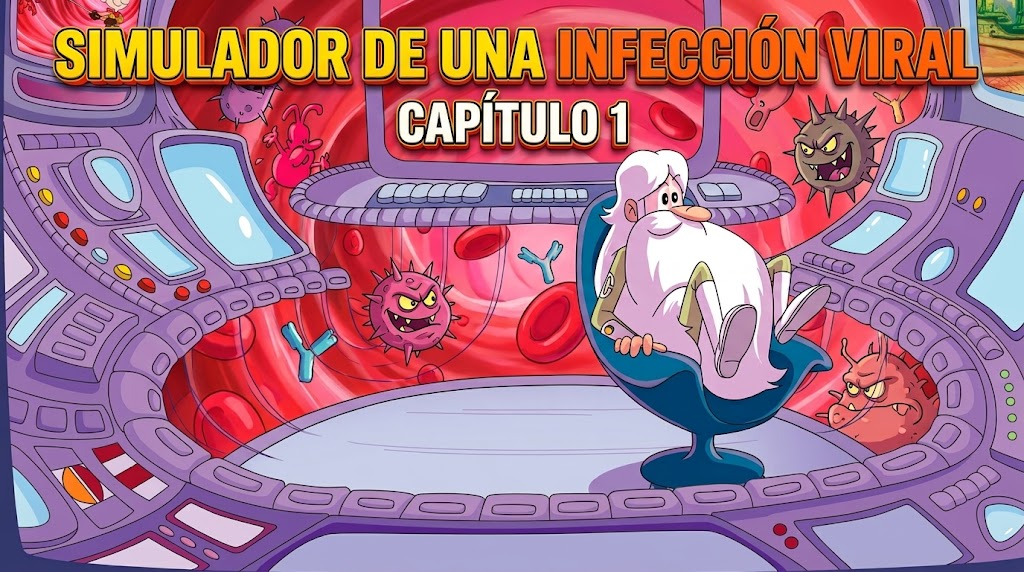


                      === TRANSMISIÓN DESDE EL NÚCLEO ===                        
┌──────────────────────────────────────────────────────────────────────────────┐
│ MAESTRO: "¡Bienvenidos a bordo de la nave de mando!                          │
│                                                                              │
│ Como comandante del sistema inmunitario, tu misión es coordinar la defensa   │
│ del organismo hora a hora contra la amenaza invasora.                        │
│                                                                              │
│ Reglas de la misión:                                                         │
│ - Dispones de 4 decisiones estratégicas en tu panel de control.              │
│ - Cada hora evaluarás el estado del cuerpo y ejecutarás una orden táctica.   │
│ - Debes controlar la carga viral evitando que el daño tisular sea fatal.     │
│ - Te daré indicaciones y consejos según cómo evolucione la batalla."         │
└─────────────────────────

Pulsa ENTER para continuar al Informe de Misión...
 
Pulsa ENTER para continuar al Informe de Misión...
 


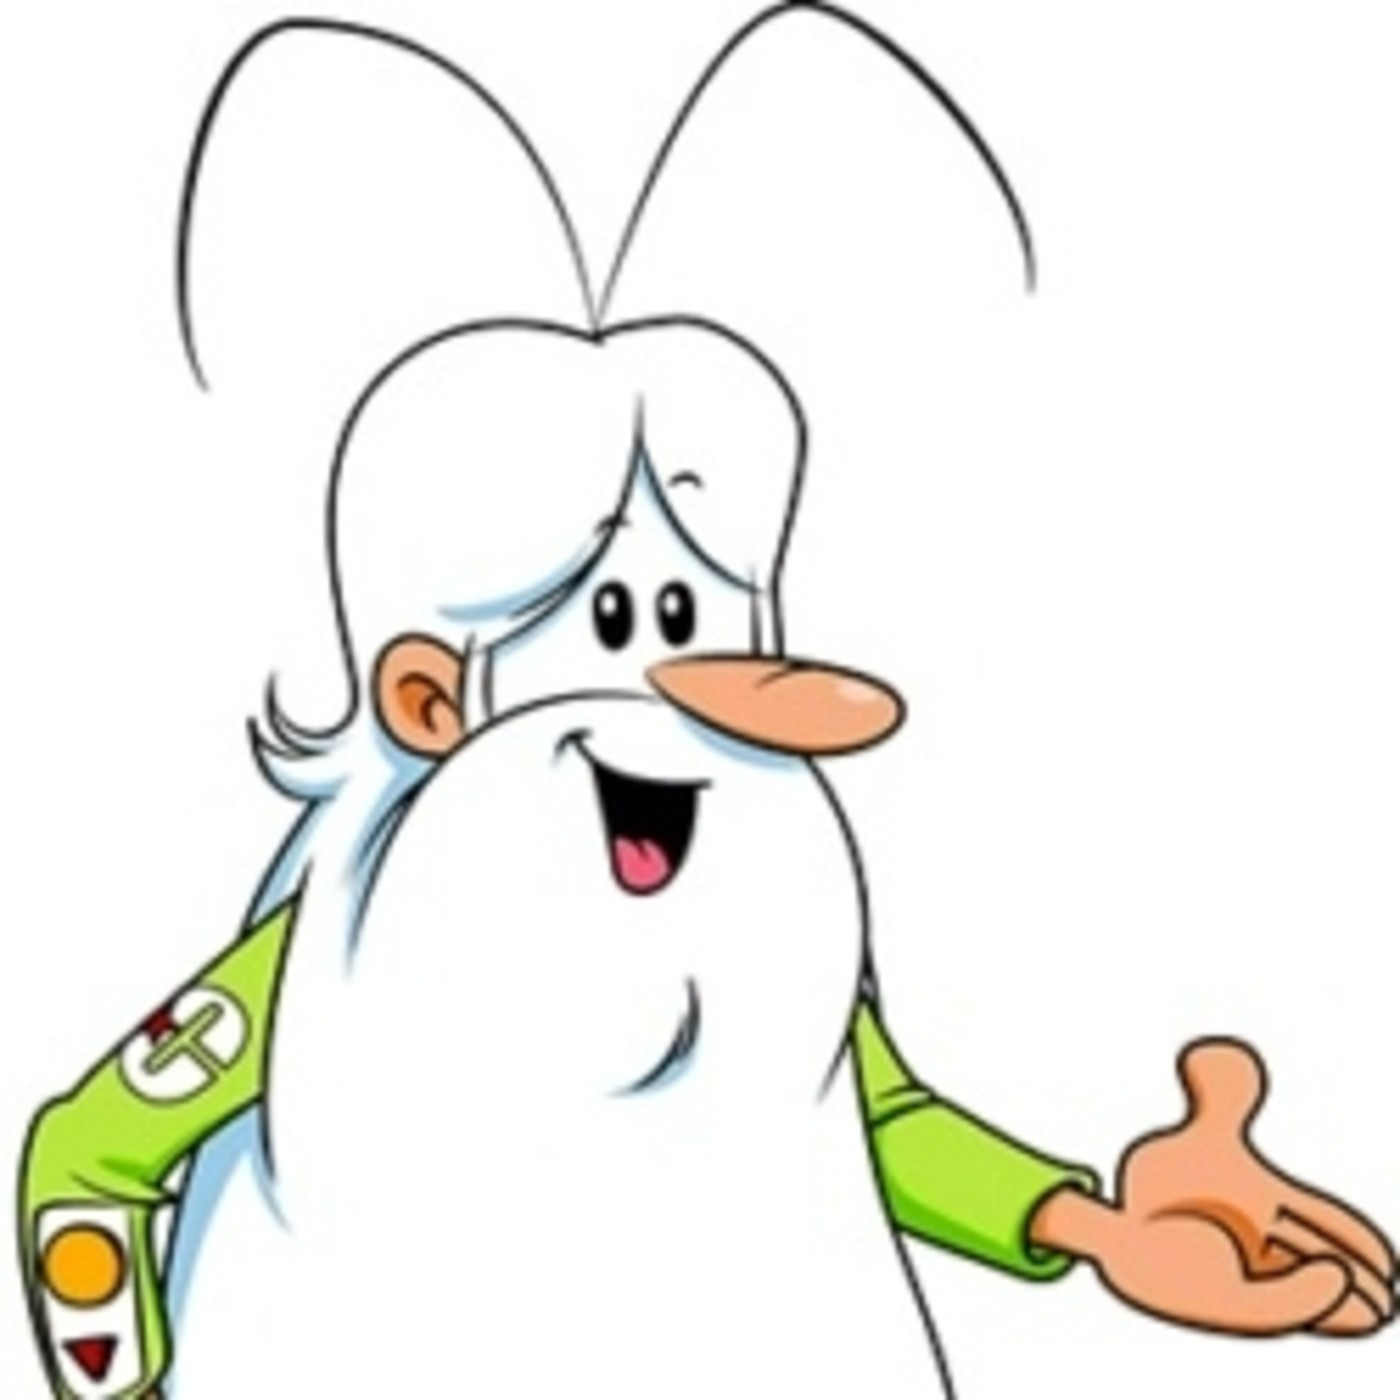


                       === CAPÍTULO 1: LA INVASIÓN ===                           
┌──────────────────────────────────────────────────────────────────────────────┐
│ MAESTRO: "¡Alarma roja en el sector respiratorio!                            │
│                                                                              │
│ Un patógeno agresivo ha logrado atravesar las barreras primarias y se está   │
│ multiplicando a una velocidad alarmante por todo el torrente sanguíneo.      │
│                                                                              │
│  CONSEJO DEL MAESTRO (Hora 1):                                               │
│ 'El virus se multiplica a gran velocidad. Antes de enviar nuestras tropas a  │
│ ciegas, debemos frenar drásticamente su ritmo de replicación.'"              │
└──────────────────────────────────────────────────────────────────────────────┘



Pulsa ENTER para iniciar los sistemas y comenzar la simulación...
 
Pulsa ENTER para iniciar los sistemas y comenzar la simulación...
 



Iniciando simulación...


=== Hora 1 ===
Virus: Virus Estándar
Carga viral: 120.0 [########################----------------]
Linfocitos T: 10.0
Células NK: 8.0
Macrófagos: 8.0
Citoquinas: 10.0
Daño tisular: 0.0 [----------------------------------------]

Acciones disponibles:
1) Activar linfocitos T (Ataque masivo especializado)
2) Potenciar células NK (Patrullas citotóxicas)
3) Activar macrófagos (Fagocitosis y alarma)
4) Aumentar interferones (Freno de replicación)


Elige una acción (1-4):  4


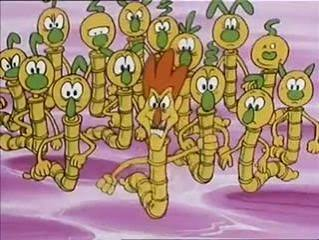


 ¡Excelente decisión! Aumentar los interferones frena la replicación viral y frena la invasión.
 Pista para la Hora 2: Con el virus frenado, necesitamos enviar a la primera línea de patrullaje a devorar al enemigo y dar la alarma.

Aumentas interferones.

=== Hora 2 ===
Virus: Virus Estándar
Carga viral: 111.2 [######################------------------]
Linfocitos T: 10.0
Células NK: 8.0
Macrófagos: 8.0
Citoquinas: 14.5
Daño tisular: 0.0 [----------------------------------------]

Acciones disponibles:
1) Activar linfocitos T (Ataque masivo especializado)
2) Potenciar células NK (Patrullas citotóxicas)
3) Activar macrófagos (Fagocitosis y alarma)
4) Aumentar interferones (Freno de replicación)


Elige una acción (1-4):  3


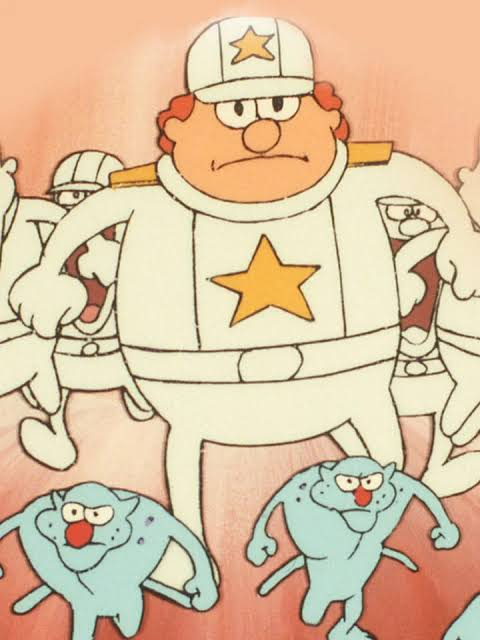


 ¡Perfecto! Los macrófagos están limpiando la zona y liberando citoquinas de alerta.
 Pista para la Hora 3: Es hora de activar las patrullas citotóxicas para buscar y destruir células infectadas.

Activas macrófagos.

=== Hora 3 ===
Virus: Virus Estándar
Carga viral: 102.8 [####################--------------------]
Linfocitos T: 10.0
Células NK: 8.0
Macrófagos: 13.0
Citoquinas: 17.1
Daño tisular: 0.0 [----------------------------------------]

Acciones disponibles:
1) Activar linfocitos T (Ataque masivo especializado)
2) Potenciar células NK (Patrullas citotóxicas)
3) Activar macrófagos (Fagocitosis y alarma)
4) Aumentar interferones (Freno de replicación)


Elige una acción (1-4):  2


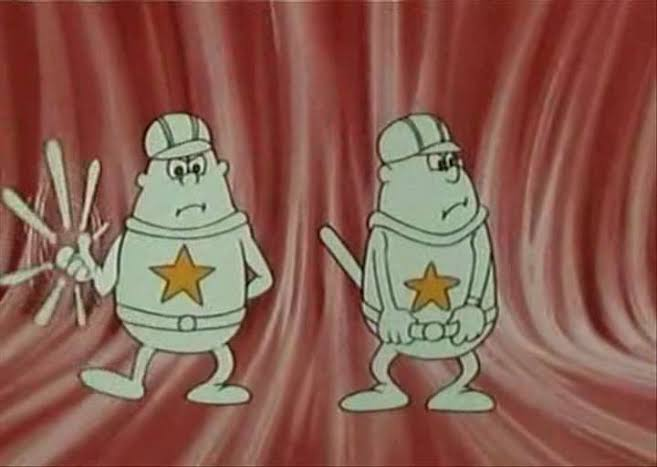


 ¡Gran maniobra! Las células NK destruyen los focos de infección antes de que se extiendan.
 Pista para la Hora 4: Para rematar la infección, despliega la respuesta adaptativa especializada.

Potencias células NK.

=== Hora 4 ===
Virus: Virus Estándar
Carga viral: 94.7 [##################----------------------]
Linfocitos T: 10.0
Células NK: 13.0
Macrófagos: 13.0
Citoquinas: 19.9
Daño tisular: 0.0 [----------------------------------------]

Acciones disponibles:
1) Activar linfocitos T (Ataque masivo especializado)
2) Potenciar células NK (Patrullas citotóxicas)
3) Activar macrófagos (Fagocitosis y alarma)
4) Aumentar interferones (Freno de replicación)


Elige una acción (1-4):  1


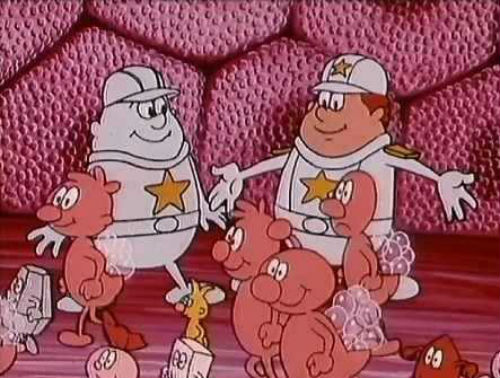


 ¡Estrategia impecable! Los linfocitos T terminan con la amenaza de forma masiva y específica.
 ¡Has completado la secuencia táctica perfecta!

Activas linfocitos T.

      RESUMEN DE LA PARTIDA
 La infección ha sido controlada con éxito.


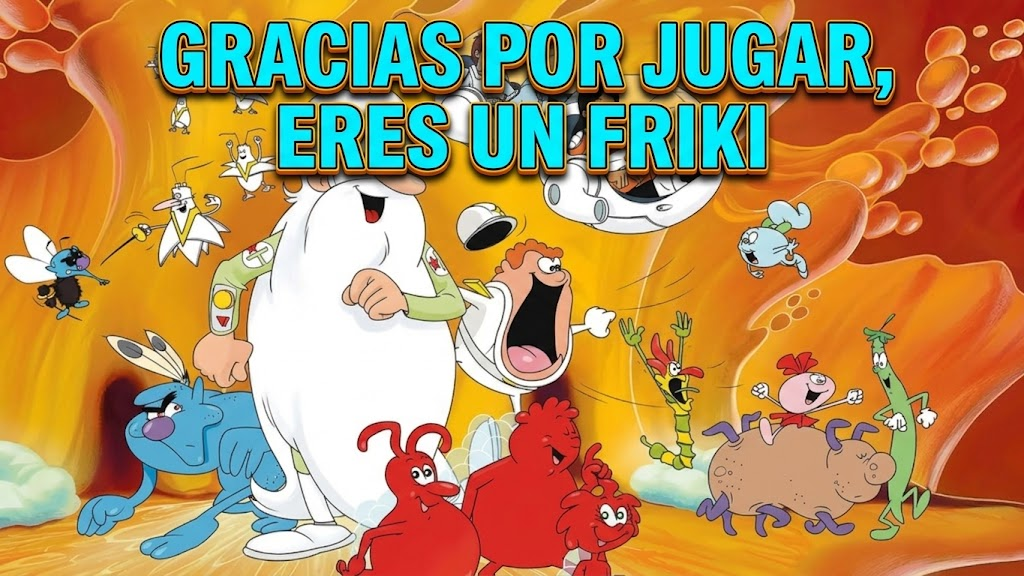


--- Estado final ---
Horas transcurridas: 4
Carga viral final: 86.5
Linfocitos T: 18.0
Células NK: 13.0
Macrófagos: 13.0
Citoquinas: 23.7
Daño tisular: 0.0

 PUNTUACIÓN DE ESTRATEGIA: 100/100
 ¡ESTRATEGIA INMUNOLÓGICA PERFECTA! Parece que no eres tan inútil como pensaba =)


 SIMULADOR DE RESPUESTA INMUNE 
1) Iniciar historia
2) Salir


KeyboardInterrupt: Interrupted by user

In [17]:
main()